# Setup

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

## Config sklearn

In [2]:
from sklearn import set_config

set_config(transform_output="pandas")

## Download competition

In [3]:
from kagglehub import competition_download

competition_name = "playground-series-s6e10"
competition_download(competition_name)

'/kaggle/input/competitions/playground-series-s6e10'

## Import competition data

### Initialize base path

In [4]:
base_path = f"../input/competitions/{competition_name}"

### Initialize train dataset

In [5]:
train_dataset_path = f"{base_path}/train.csv"
train_dataset = pd.read_csv(train_dataset_path)

train_dataset = train_dataset.dropna()

### Initialize test dataset

In [6]:
test_dataset_path = f"{base_path}/test.csv"
test_dataset = pd.read_csv(test_dataset_path)

# Research data

## Features extraction from dataset

### Feature extraction function

In [7]:
def extract_features(dataset: pd.DataFrame):
    return dataset.drop(["id", "satisfaction"], axis=1)

### Extracted features

In [8]:
X = extract_features(train_dataset)

## Target extraction from dataset

### Target extraction function

In [9]:
def extract_target(dataset: pd.DataFrame):
    return dataset["satisfaction"]

### Extracted target

In [10]:
y = extract_target(train_dataset)

## Explore features distributions

### Histogram plot function for dataset

In [11]:
import matplotlib.pyplot as plt


def plot_histograms_for_features(dataset: pd.DataFrame, features_names: list = [], stat: str = "count"):
    features_names = dataset.columns.to_list() if not features_names else features_names

    for feature_name in features_names:
        plt.figure()

        sns.histplot(data=dataset, x=feature_name, stat=stat)
        
        title = f"{stat} histogram for {feature_name} feature"
        plt.title(title)
        
        plt.show()


### Plot histograms for dataset

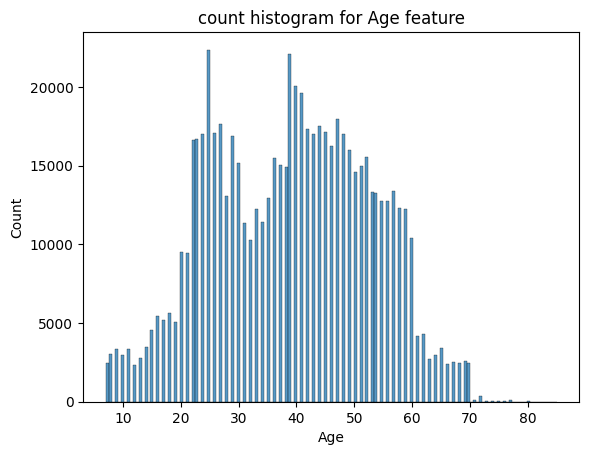

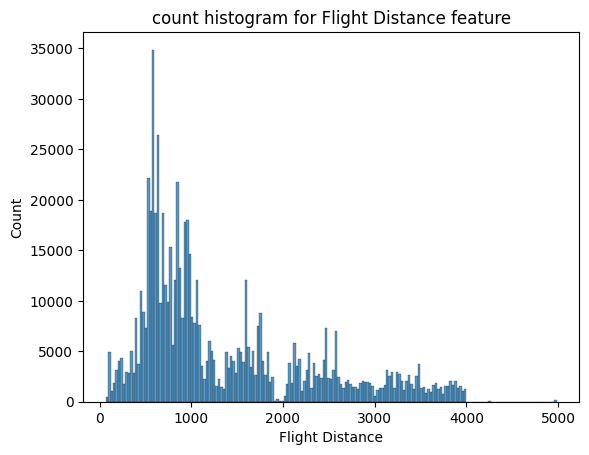

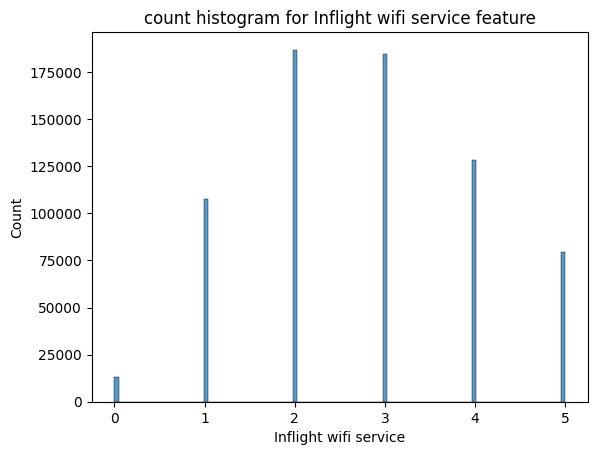

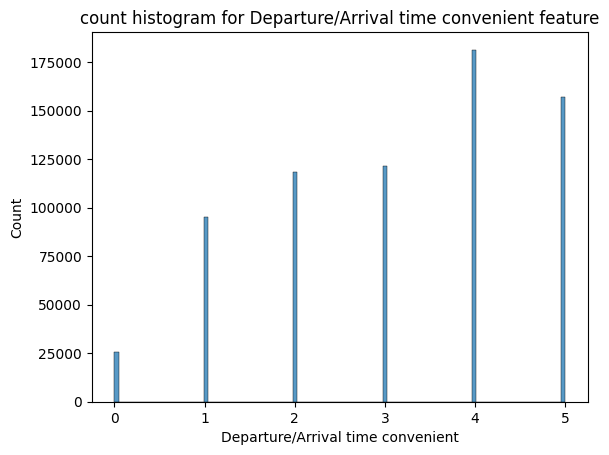

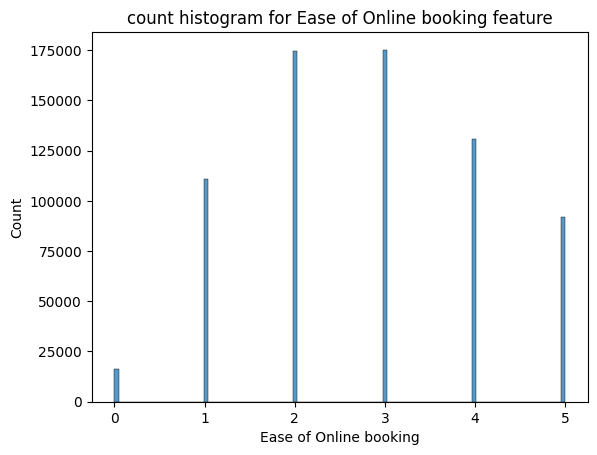

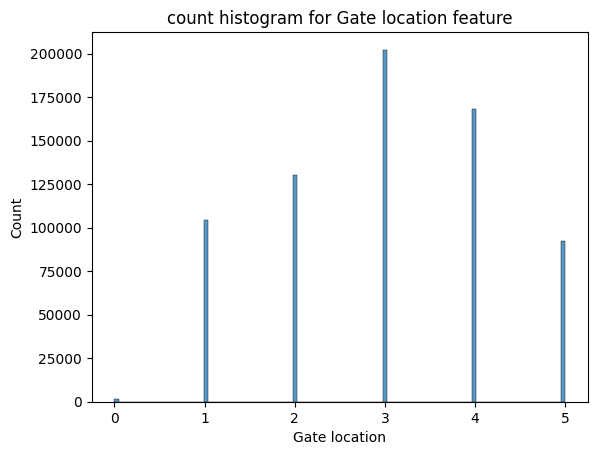

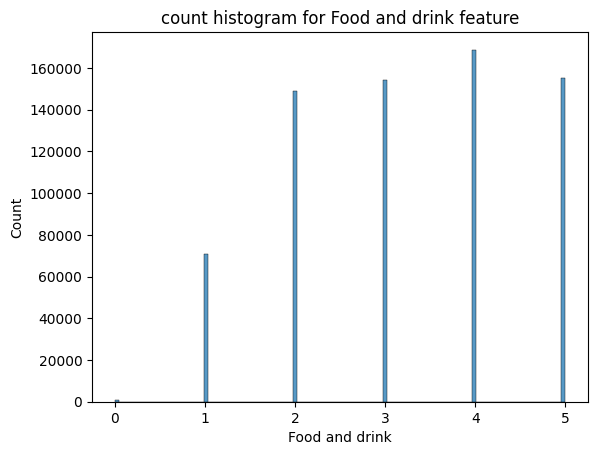

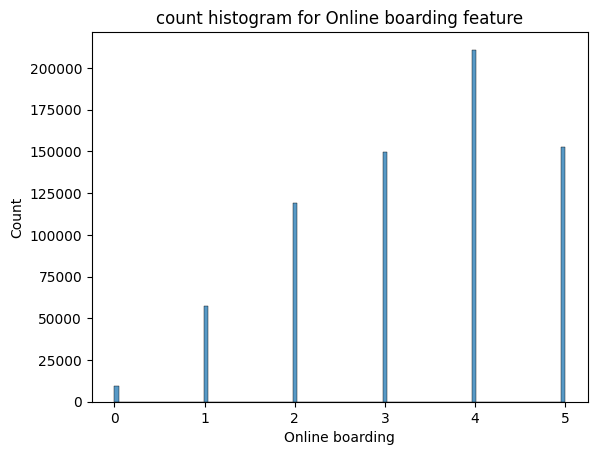

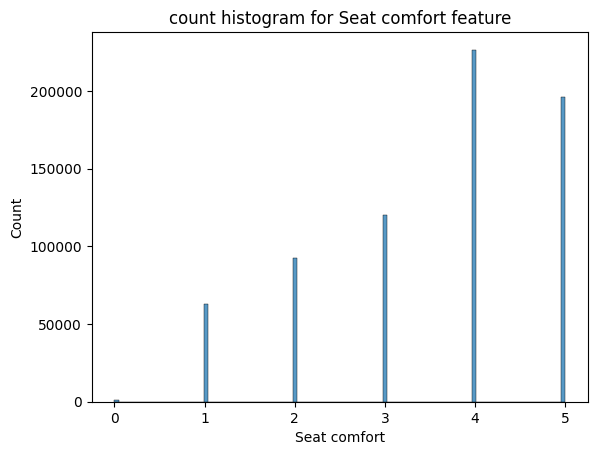

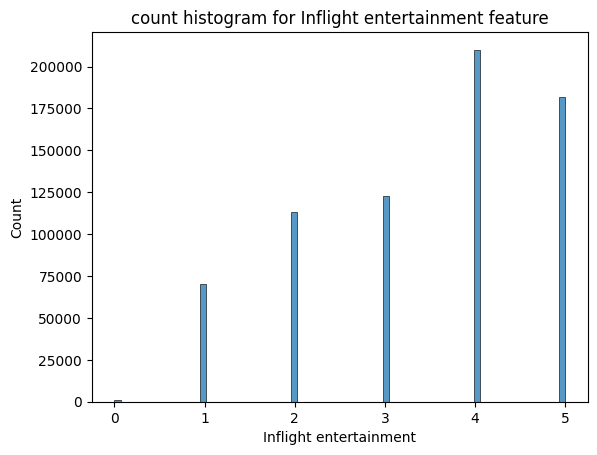

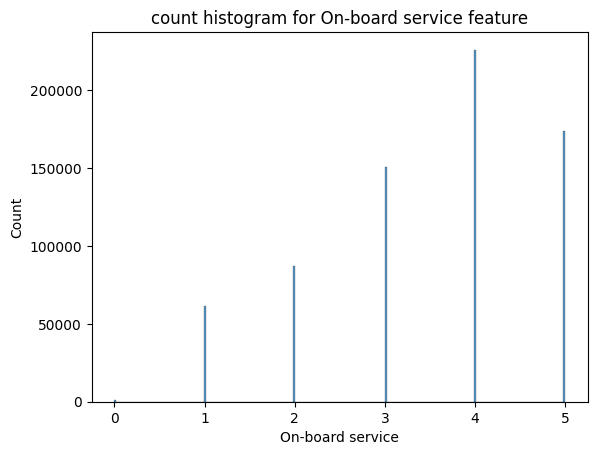

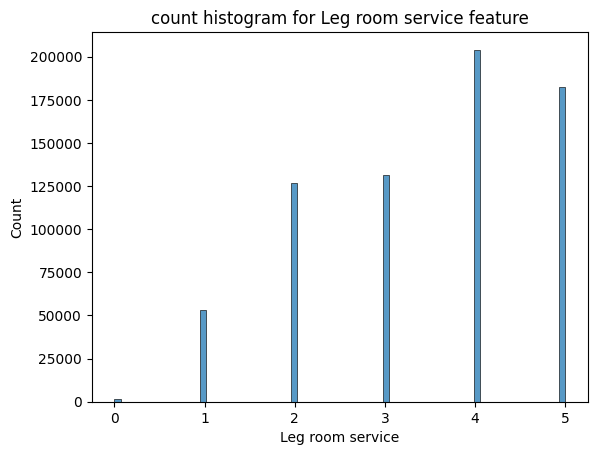

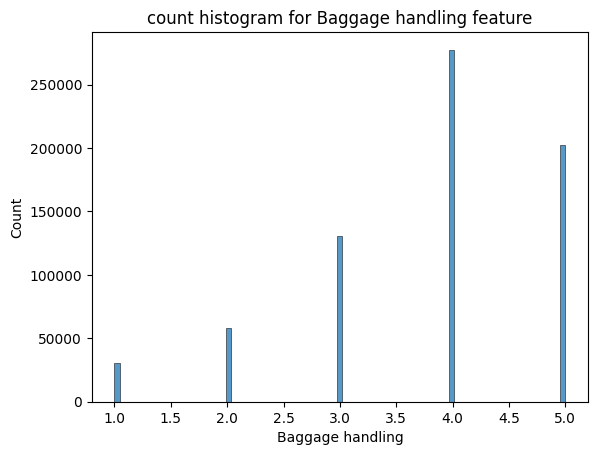

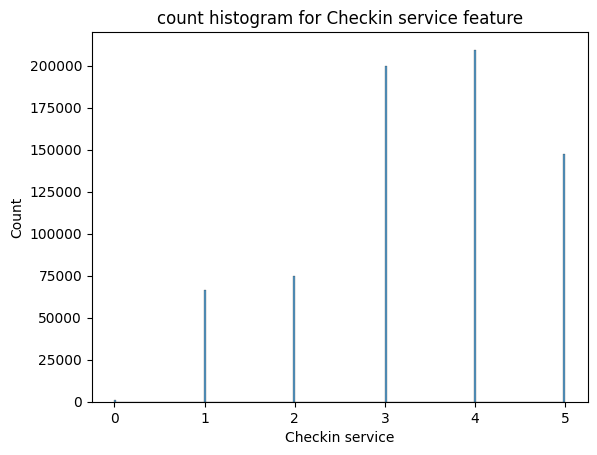

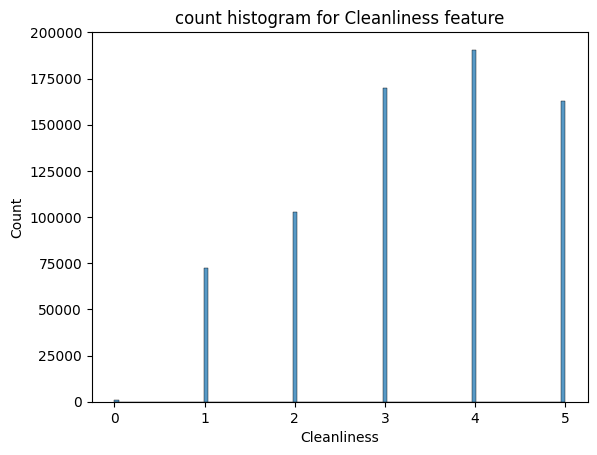

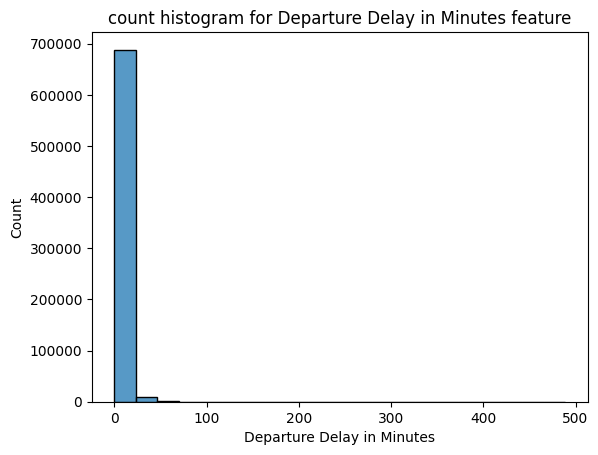

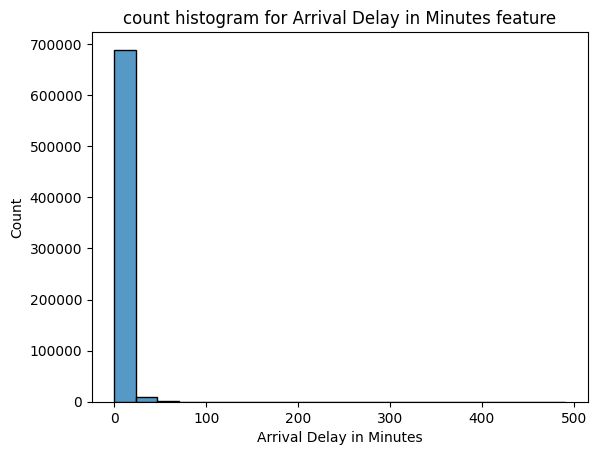

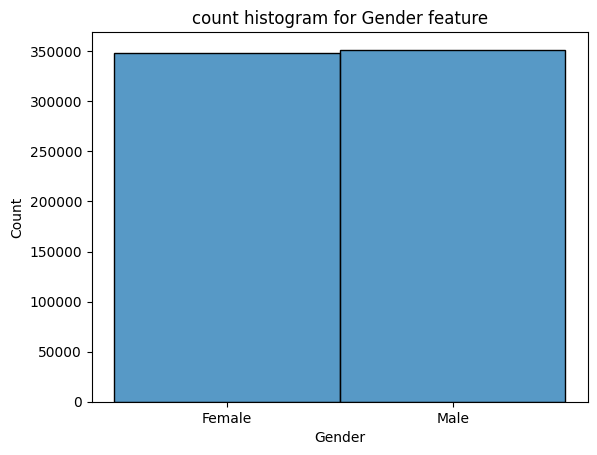

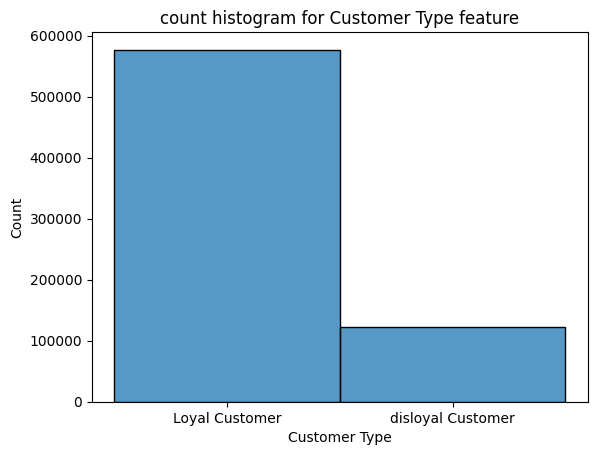

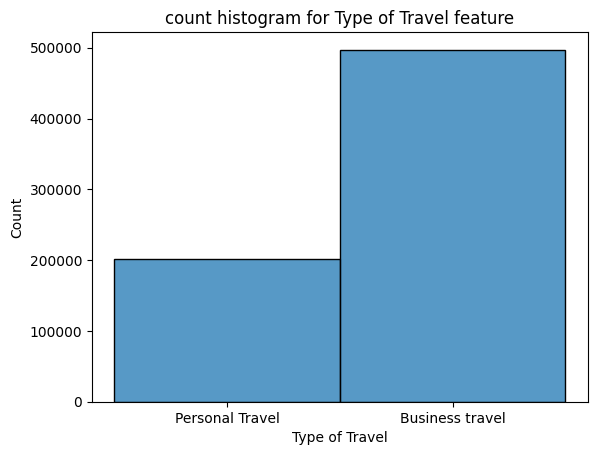

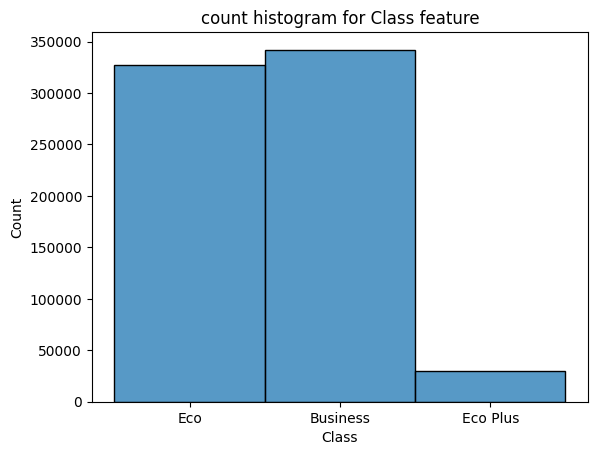

In [12]:
plot_histograms_for_features(X)

## Prepare data for analysis

In [13]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline


def prepare_data_for_analysis(X, y):
    transformer = prepare_transformer_for_analysis()
    return transformer.fit_transform(X, y)
    

def prepare_transformer_for_analysis():
    number_transformer = prepare_number_transfomer_for_analysis()
    category_transformer = prepare_category_transformer_for_analysis()
    transformer = make_column_transformer(number_transformer, category_transformer, remainder="passthrough", verbose_feature_names_out=False)
    return transformer


def prepare_number_transfomer_for_analysis():
    number_preprocessing = SimpleImputer(strategy="constant", fill_value=0)
    number_column_selector = make_column_selector(dtype_include=["number"])
    number_transformer = (number_preprocessing, number_column_selector)
    return number_transformer


def prepare_category_transformer_for_analysis():
    category_preprocessing = prepare_category_preprocessing_for_analysis()
    category_column_selector = make_column_selector(dtype_include=["object", "string", "category"])
    category_transformer = (category_preprocessing, category_column_selector)
    return category_transformer
    

def prepare_category_preprocessing_for_analysis():
    category_imputer = SimpleImputer(strategy="constant", fill_value="unknown")
    category_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1)
    category_transformer = make_pipeline(category_imputer, category_encoder)
    return category_transformer

## Mutual information analysis

In [14]:
from sklearn.feature_selection import mutual_info_classif


def analyze_mutual_information(X, y):
    prepared_X = prepare_data_for_analysis(X, y)
    mutual_info = mutual_info_classif(prepared_X, y)
    mutual_info_result = pd.Series(mutual_info, index=X.columns).sort_values(ascending=False)
    return mutual_info_result

In [15]:
analyze_mutual_information(X, y)

Online boarding                      0.262825
Class                                0.201134
Type of Travel                       0.143236
Inflight wifi service                0.141202
Inflight entertainment               0.131718
Seat comfort                         0.123490
Flight Distance                      0.111355
On-board service                     0.093190
Leg room service                     0.085689
Cleanliness                          0.083939
Baggage handling                     0.071906
Ease of Online booking               0.069030
Age                                  0.062210
Checkin service                      0.061269
Gender                               0.058327
Food and drink                       0.046941
Customer Type                        0.036623
Gate location                        0.036158
Departure/Arrival time convenient    0.020824
Arrival Delay in Minutes             0.002592
Departure Delay in Minutes           0.001264
dtype: float64

## f_classif analysis

In [16]:
from sklearn.feature_selection import f_classif


def analyze_f_classif_p_value(X, y):
    prepared_X = prepare_data_for_analysis(X, y)
    _, p_value = f_classif(prepared_X, y)
    f_classif_result = pd.Series(p_value, index=X.columns).sort_values(ascending=False)
    return f_classif_result

In [17]:
analyze_f_classif_p_value(X, y)

Gender                                1.268821e-20
Gate location                         3.465400e-81
Departure Delay in Minutes           2.018595e-199
Flight Distance                       0.000000e+00
Age                                   0.000000e+00
Ease of Online booking                0.000000e+00
Departure/Arrival time convenient     0.000000e+00
Inflight wifi service                 0.000000e+00
Food and drink                        0.000000e+00
Inflight entertainment                0.000000e+00
On-board service                      0.000000e+00
Online boarding                       0.000000e+00
Seat comfort                          0.000000e+00
Baggage handling                      0.000000e+00
Leg room service                      0.000000e+00
Cleanliness                           0.000000e+00
Checkin service                       0.000000e+00
Arrival Delay in Minutes              0.000000e+00
Customer Type                         0.000000e+00
Type of Travel                 

## Chi2 analysis

In [18]:
from sklearn.feature_selection import chi2


def analyze_chi2_p_value(X, y):
    prepared_X = prepare_data_for_analysis(X, y)
    prepared_X["Arrival Delay in Minutes"] = prepared_X["Arrival Delay in Minutes"].round().astype("int64")
    
    _, p_value = chi2(prepared_X, y)
    chi2_result = pd.Series(p_value, index=X.columns).sort_values(ascending=False)
    return chi2_result

In [19]:
analyze_chi2_p_value(X, y)

Gender                                5.173921e-11
Gate location                         3.222620e-43
Departure/Arrival time convenient    1.327180e-255
Age                                   0.000000e+00
Flight Distance                       0.000000e+00
Ease of Online booking                0.000000e+00
Inflight wifi service                 0.000000e+00
Online boarding                       0.000000e+00
Food and drink                        0.000000e+00
Inflight entertainment                0.000000e+00
On-board service                      0.000000e+00
Leg room service                      0.000000e+00
Seat comfort                          0.000000e+00
Baggage handling                      0.000000e+00
Checkin service                       0.000000e+00
Departure Delay in Minutes            0.000000e+00
Cleanliness                           0.000000e+00
Arrival Delay in Minutes              0.000000e+00
Customer Type                         0.000000e+00
Type of Travel                 

## SHAP analysis

In [20]:
import shap
import matplotlib.pyplot as plt


def shap_tree_analysis(model, X, y):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X)
    plot_shap_bar(shap_values, X, y, X.columns.size)
    shap.plots.beeswarm(shap_values, max_display=X.columns.size)


def plot_shap_bar(shap_values, X, y, features_to_display, clustering_cutoff=0.5):
    shap.plots.bar(shap_values, max_display=features_to_display)
    shap.plots.bar(shap_values.abs.max(0))

### SHAP XGBoost analysis

In [21]:
from xgboost import XGBClassifier


def analyze_xgboost_shap(X, y):
    prepared_X = prepare_data_for_analysis(X, y)
    model = XGBClassifier().fit(prepared_X, y)
    shap_tree_analysis(model, prepared_X, y)

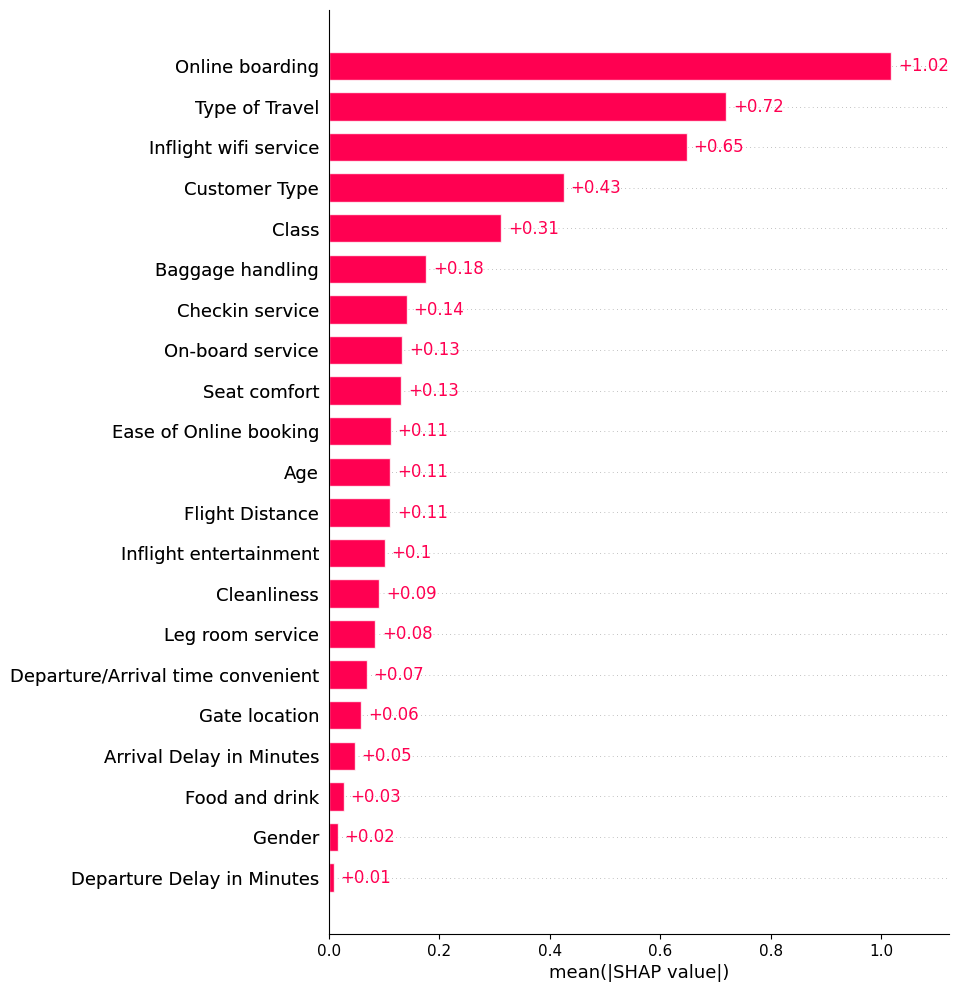

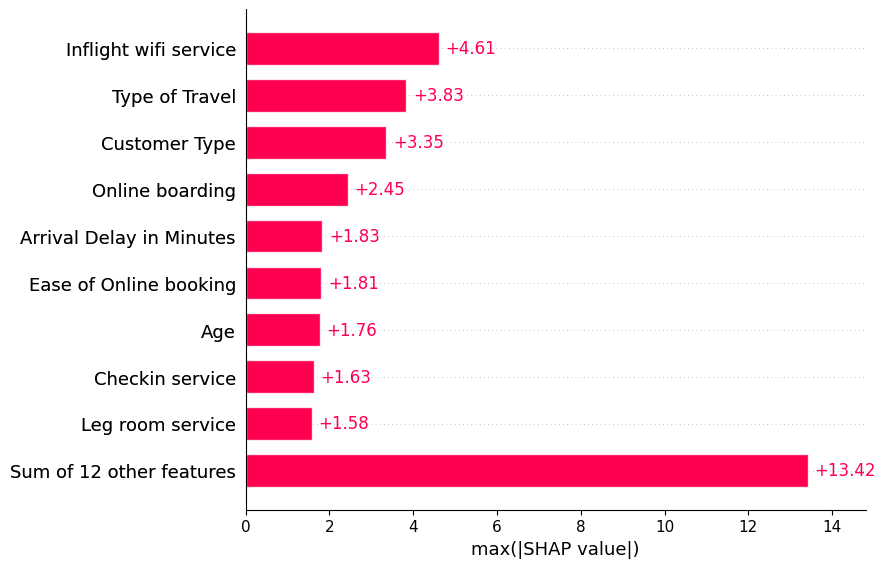

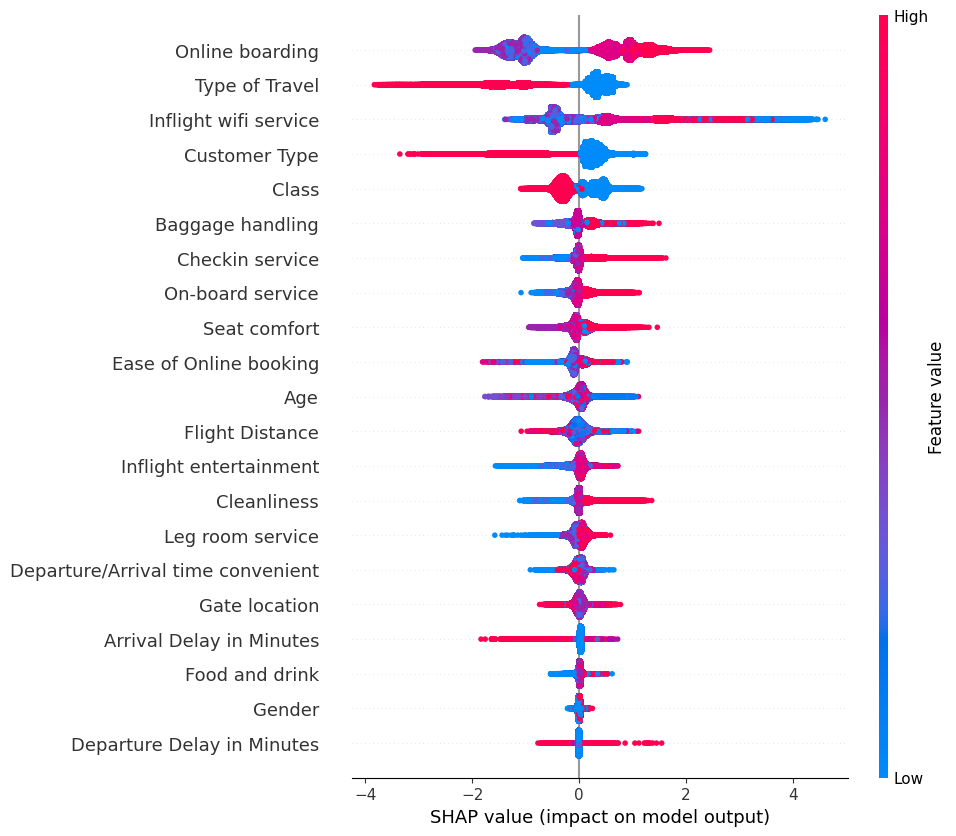

In [22]:
analyze_xgboost_shap(X, y)

### SHAP CatBoost analysis

In [23]:
from catboost import CatBoostClassifier


def analyze_catboost_shap(X, y):
    prepared_X = prepare_data_for_catboost(X, y)
    cat_features = select_cat_features_for_cat_boost(prepared_X)
    model = CatBoostClassifier(cat_features=cat_features, silent=True)
    model.fit(prepared_X, y)
    shap_tree_analysis(model, prepared_X, y)


def prepare_data_for_catboost(X, y):
    number_imputer = SimpleImputer(strategy="constant", fill_value = 0)
    number_column = make_column_selector(dtype_include=["number"])
    number_transformer = (number_imputer, number_column)
    
    transformer = make_column_transformer(
        number_transformer,
        remainder="passthrough", verbose_feature_names_out=False
    )
    prepared_X = transformer.fit_transform(X, y)
    return prepared_X


def select_cat_features_for_cat_boost(dataset):
    cat_features = make_column_selector(dtype_include=["string", "object", "category"])(dataset)
    return cat_features

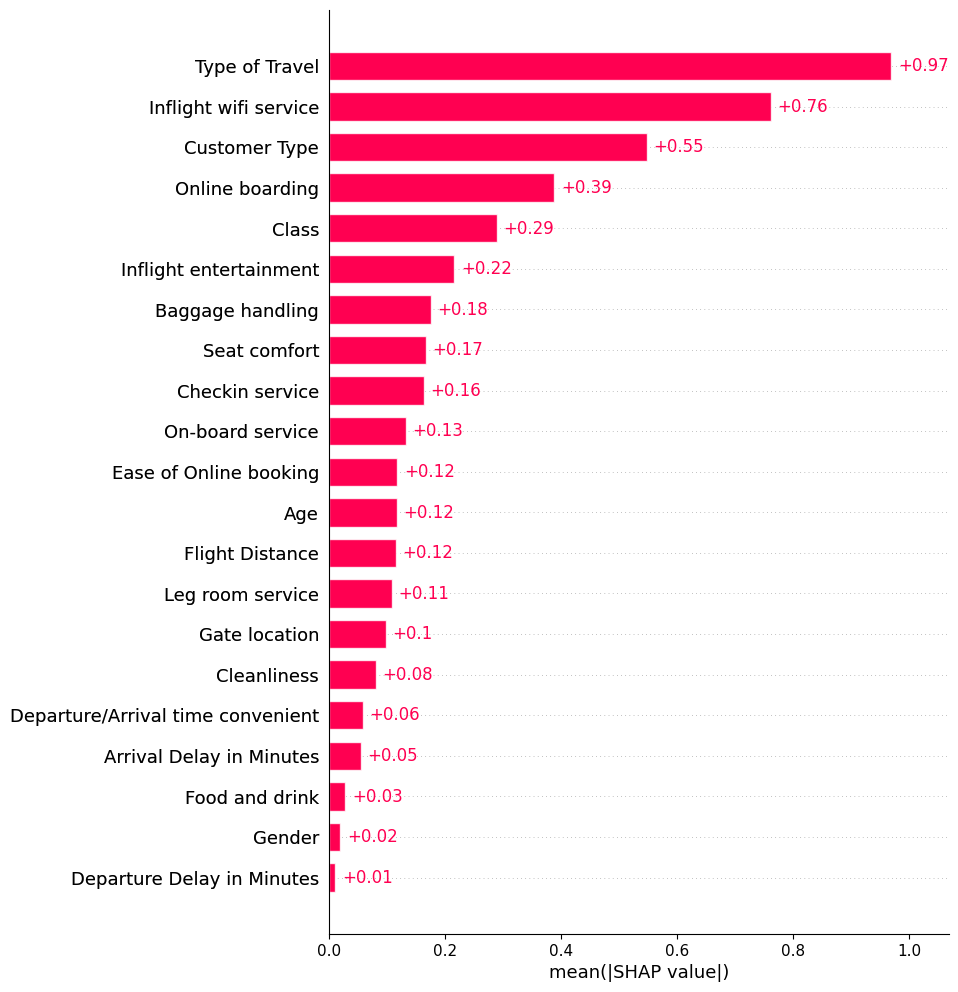

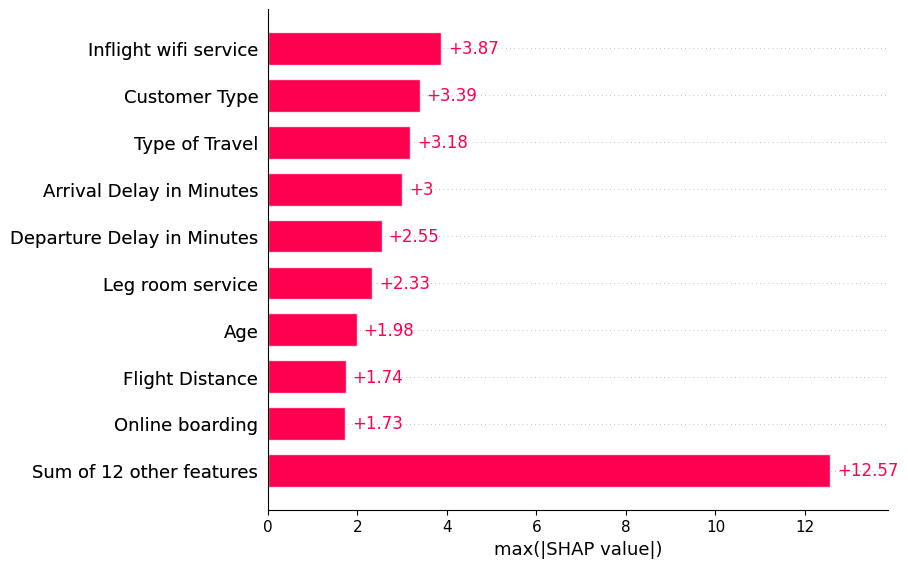

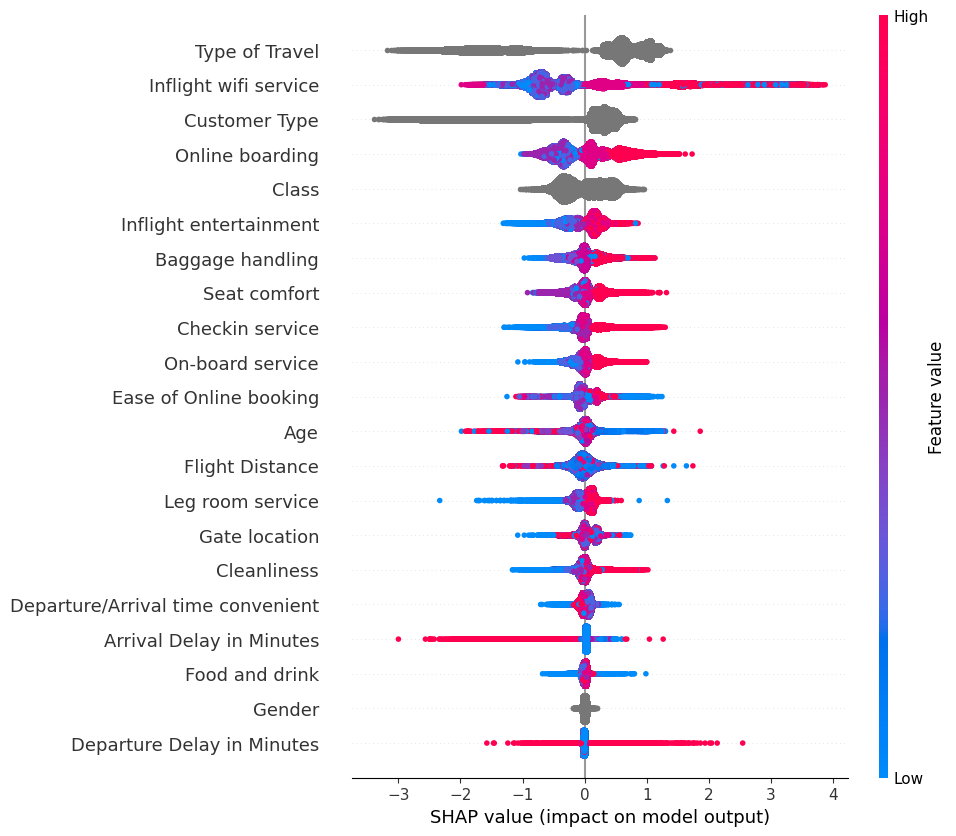

In [24]:
analyze_catboost_shap(X, y)

# Feature Engineering

## Cluster feature combination

In [29]:
from sklearn.preprocessing import FunctionTransformer
from functools import reduce


def prepare_feature_combinator(combinations = {}):
    if combinations:
        combine_features = prepare_combine_features(combinations)
        feature_combinator = FunctionTransformer(combine_features)
    else:
        feature_combinator = FunctionTransformer()

    return feature_combinator


def prepare_combine_features(combinations = {}):
    def combine_features(dataset):
        updated_dataset = dataset.copy()
        for combination, features in combinations.items():
            updated_dataset[combination] = reduce(
                lambda combined_feature, other: combined_feature + " " + updated_dataset[other].astype("string").fillna("unknown"),
                features[1:],
                updated_dataset[features[0]].astype("string").fillna("unknown")
            )
        return updated_dataset
    return combine_features

In [26]:
def make_standard_combinations(dataset):
    combinations = {}
    
    feature_combinator = prepare_feature_combinator(combinations)
    updated_dataset = feature_combinator.fit_transform(dataset)
    return updated_dataset

In [27]:
X_with_standard_combinations = make_standard_combinations(X)

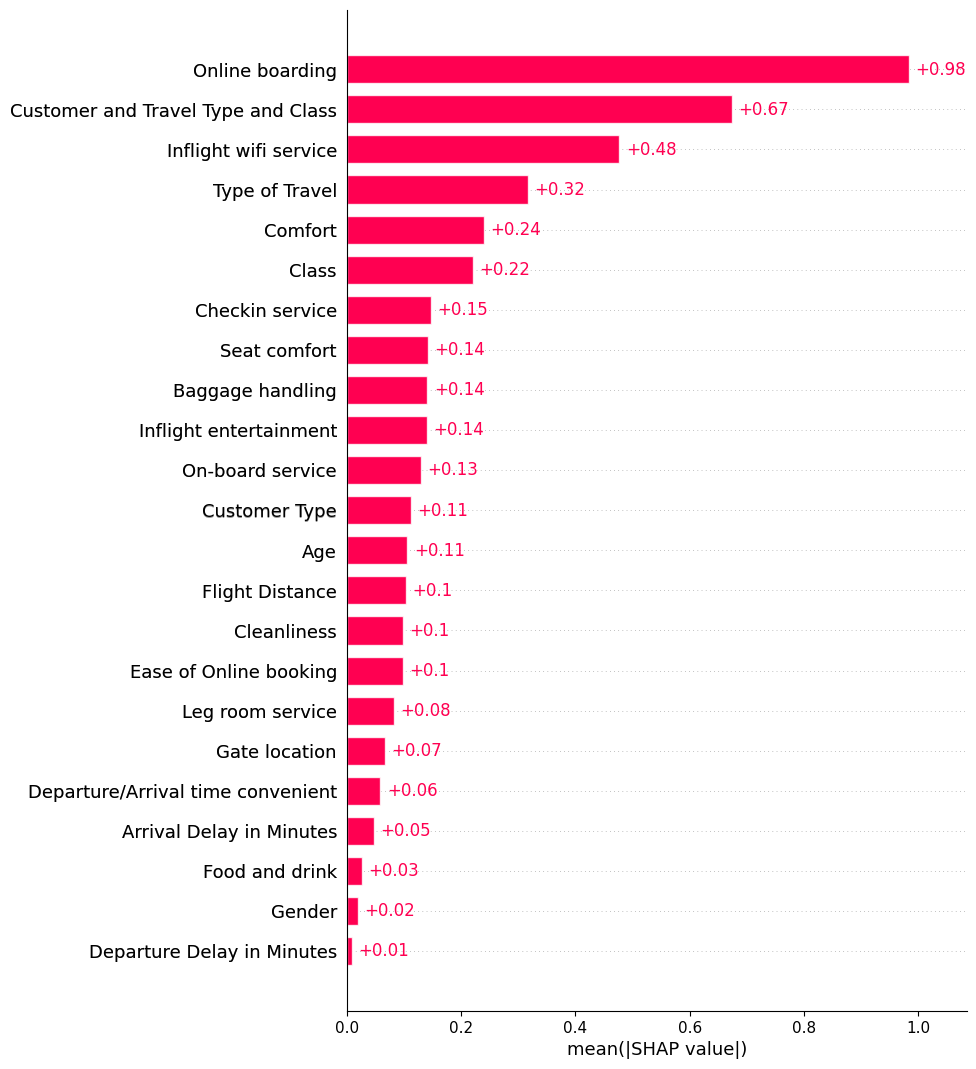

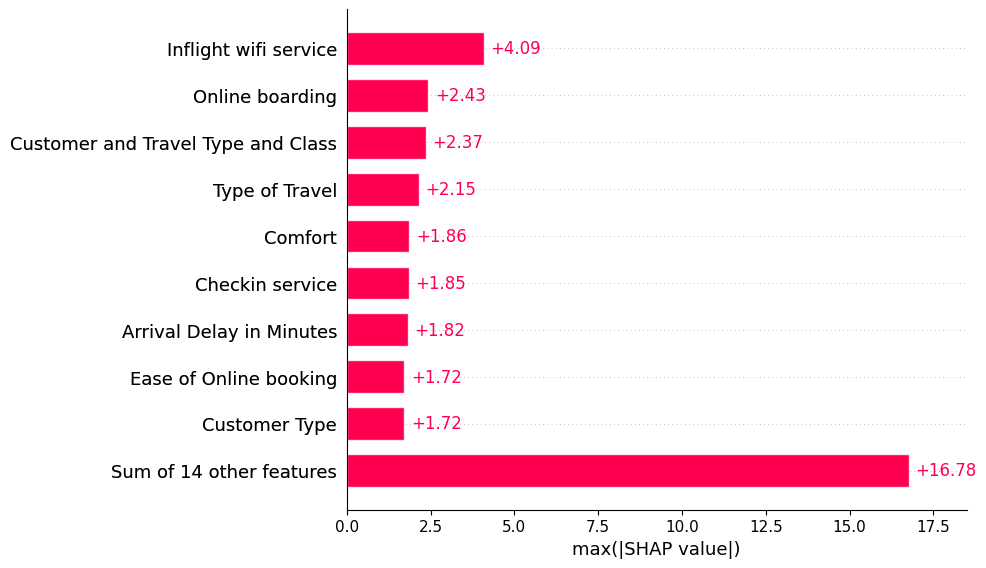

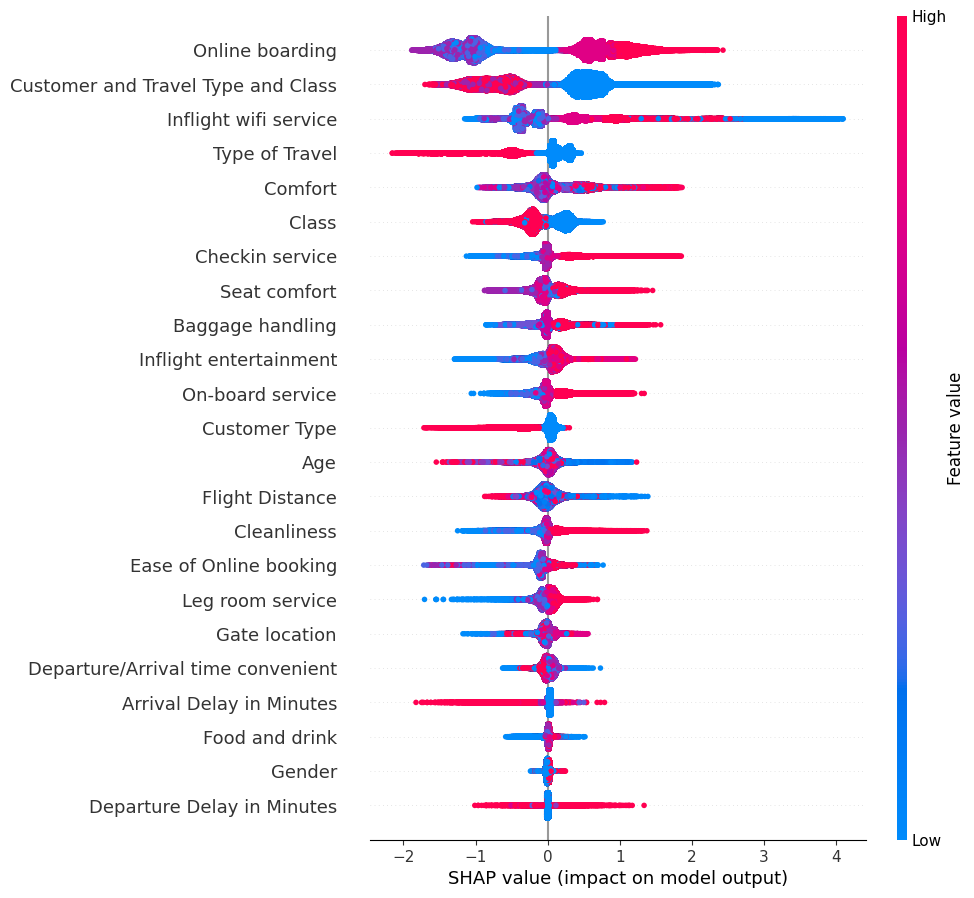

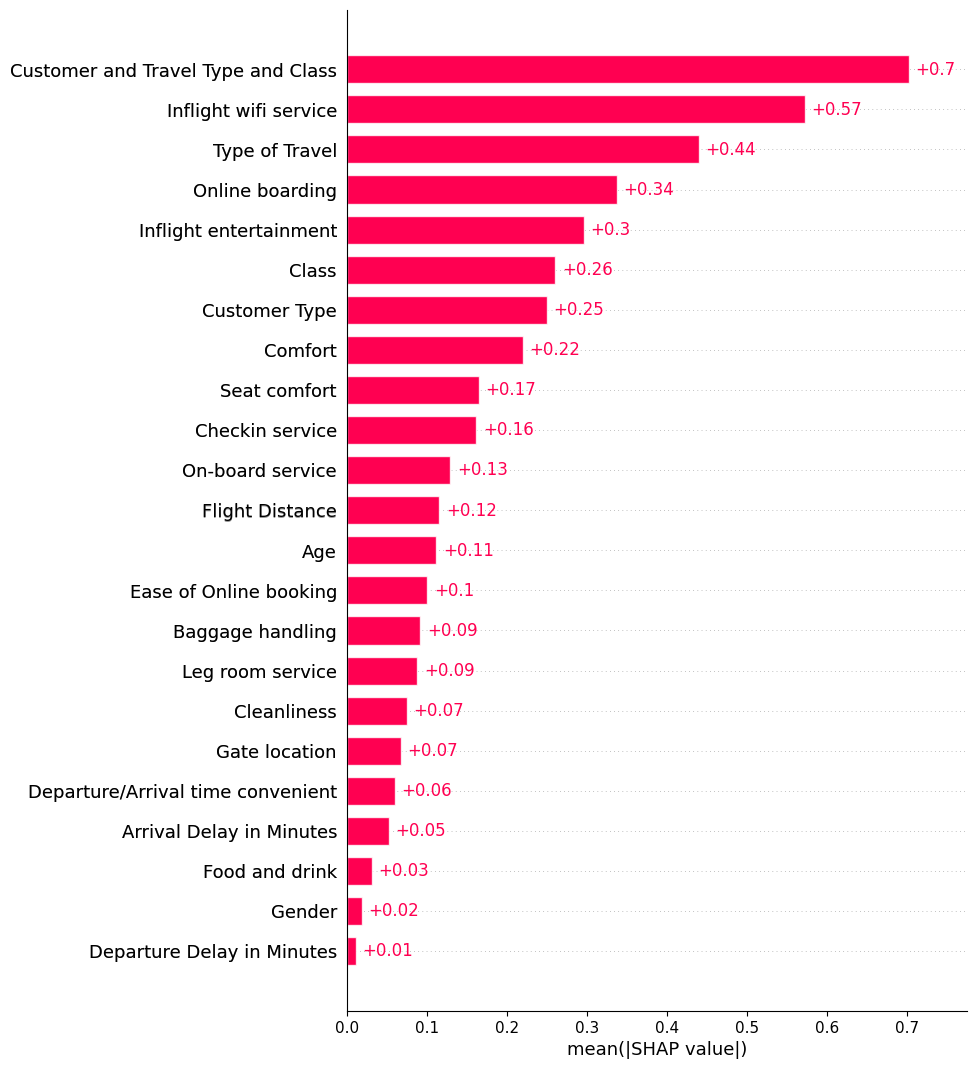

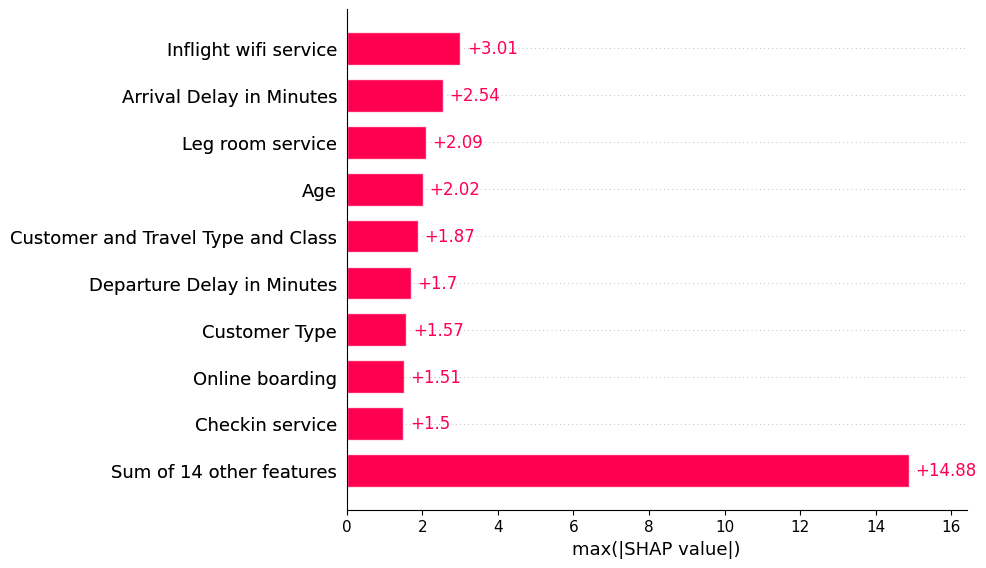

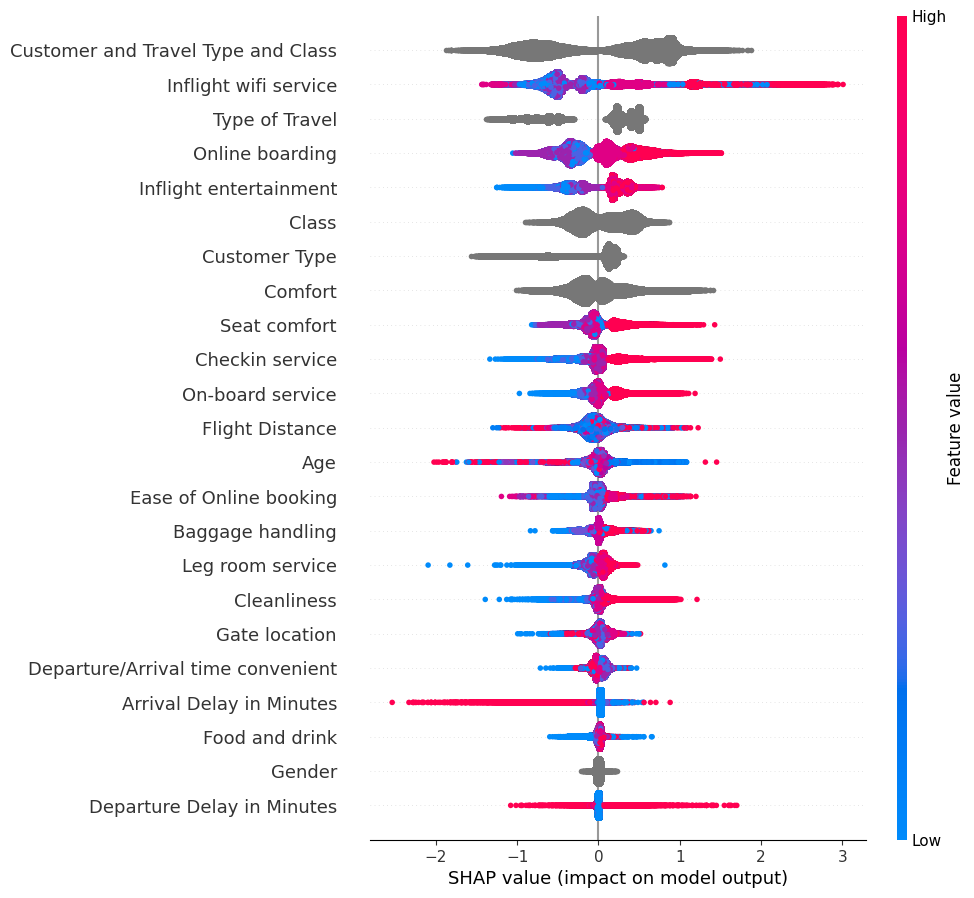

In [81]:
analyze_xgboost_shap(X_with_standard_combinations, y)
analyze_catboost_shap(X_with_standard_combinations, y)

In [28]:
from sklearn.compose import make_column_transformer


def prepare_caster_to_categories(features_to_cast = []):
    if features_to_cast:
        cast_to_categories_transformer = FunctionTransformer(cast_to_categories)
        caster_to_categories = make_column_transformer(
            (cast_to_categories_transformer, features_to_cast),
            verbose_feature_names_out=False,
            remainder="passthrough"
        )
    else:
        caster_to_categories=FunctionTransformer()
    return caster_to_categories


def cast_to_categories(dataset):
    updated_dataset = dataset.astype("string").fillna("unknown").astype("category")
    return updated_dataset

In [83]:
from sklearn.model_selection import train_test_split
from catboost import Pool

features_to_cast = [
    # "Inflight wifi service",
    # "Departure/Arrival time convenient",
    # "Ease of Online booking",
    # "Gate location",
    # "Food and drink",
    # "Online boarding",
    # "Seat comfort",
    # "Inflight entertainment",
    # "On-board service",
    # "Leg room service",
    # "Baggage handling",
    # "Checkin service",
    # "Cleanliness",   
]

features_to_cast += select_cat_features_for_cat_boost(X_with_standard_combinations)
print(features_to_cast)

caster_to_categories = prepare_caster_to_categories(features_to_cast)
modified_X = prepare_data_for_catboost(X_with_standard_combinations, y)
modified_X = caster_to_categories.fit_transform(modified_X, y)
train_modified_X, validation_modified_X, train_y, validation_y = train_test_split(modified_X, y, test_size = 0.3)

cat_features = select_cat_features_for_cat_boost(train_modified_X)

model = CatBoostClassifier(eval_metric="AUC", cat_features=cat_features)
model.fit(train_modified_X, train_y, eval_set=Pool(validation_modified_X, validation_y, cat_features=cat_features))

['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Customer and Travel Type and Class', 'Comfort']
Learning rate set to 0.146314
0:	test: 0.9358103	best: 0.9358103 (0)	total: 335ms	remaining: 5m 34s
1:	test: 0.9414985	best: 0.9414985 (1)	total: 658ms	remaining: 5m 28s
2:	test: 0.9454105	best: 0.9454105 (2)	total: 905ms	remaining: 5m
3:	test: 0.9462998	best: 0.9462998 (3)	total: 1.22s	remaining: 5m 3s
4:	test: 0.9481323	best: 0.9481323 (4)	total: 1.52s	remaining: 5m 2s
5:	test: 0.9493660	best: 0.9493660 (5)	total: 1.79s	remaining: 4m 56s
6:	test: 0.9500729	best: 0.9500729 (6)	total: 2.06s	remaining: 4m 51s
7:	test: 0.9506645	best: 0.9506645 (7)	total: 2.34s	remaining: 4m 50s
8:	test: 0.9510668	best: 0.9510668 (8)	total: 2.63s	remaining: 4m 49s
9:	test: 0.9516225	best: 0.9516225 (9)	total: 2.93s	remaining: 4m 50s
10:	test: 0.9519093	best: 0.9519093 (10)	total: 3.19s	remaining: 4m 47s
11:	test: 0.9520849	best: 0.9520849 (11)	total: 3.48s	remaining: 4m 46s
12:	test: 0.9523177	best: 0.

CatBoostClassifier(cat_features=['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Customer and Travel Type and Class', 'Comfort'], eval_metric='AUC')

In [84]:
xgb_classifier = XGBClassifier(n_estimators=1000, learning_rate = 0.02, enable_categorical=True, eval_metric="auc", objective='binary:logistic')
xgb_classifier.fit(train_modified_X, train_y, eval_set=[(validation_modified_X, validation_y)])

[0]	validation_0-auc:0.95017
[1]	validation_0-auc:0.95015
[2]	validation_0-auc:0.95038
[3]	validation_0-auc:0.95044
[4]	validation_0-auc:0.95056
[5]	validation_0-auc:0.95059
[6]	validation_0-auc:0.95059
[7]	validation_0-auc:0.95074
[8]	validation_0-auc:0.95071
[9]	validation_0-auc:0.95090
[10]	validation_0-auc:0.95093
[11]	validation_0-auc:0.95097
[12]	validation_0-auc:0.95102
[13]	validation_0-auc:0.95115
[14]	validation_0-auc:0.95115
[15]	validation_0-auc:0.95123
[16]	validation_0-auc:0.95144
[17]	validation_0-auc:0.95145
[18]	validation_0-auc:0.95154
[19]	validation_0-auc:0.95154
[20]	validation_0-auc:0.95157
[21]	validation_0-auc:0.95164
[22]	validation_0-auc:0.95167
[23]	validation_0-auc:0.95210
[24]	validation_0-auc:0.95216
[25]	validation_0-auc:0.95228
[26]	validation_0-auc:0.95234
[27]	validation_0-auc:0.95242
[28]	validation_0-auc:0.95247
[29]	validation_0-auc:0.95252
[30]	validation_0-auc:0.95256
[31]	validation_0-auc:0.95258
[32]	validation_0-auc:0.95265
[33]	validation_0-au

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.02, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=None, num_parallel_tree=None, ...)

In [100]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score


mlp_X = prepare_data_for_analysis(modified_X, y)
train_mlp_X, valid_mlp_X, train_mlp_y, valid_mlp_y = train_test_split(mlp_X, y, test_size=0.3)
mlp_clf = MLPClassifier(max_iter=1000).fit(train_mlp_X, train_mlp_y)
prediction = mlp_clf.predict_proba(valid_mlp_X)
print(roc_auc_score(valid_mlp_y, prediction[:, 1]))

0.9534840688421126


In [103]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier().fit(train_mlp_X, train_mlp_y)
prediction = rf_clf.predict_proba(valid_mlp_X)
print(roc_auc_score(valid_mlp_y, prediction[:, 1]))

0.9544386120835456


In [105]:
xgb_clf = XGBClassifier().fit(train_mlp_X, train_mlp_y)
catboost_clf = CatBoostClassifier().fit(train_mlp_X, train_mlp_y)

Learning rate set to 0.145035
0:	learn: 0.5545630	total: 81.6ms	remaining: 1m 21s
1:	learn: 0.4658010	total: 161ms	remaining: 1m 20s
2:	learn: 0.4065270	total: 244ms	remaining: 1m 21s
3:	learn: 0.3686618	total: 325ms	remaining: 1m 20s
4:	learn: 0.3421141	total: 402ms	remaining: 1m 20s
5:	learn: 0.3207647	total: 483ms	remaining: 1m 20s
6:	learn: 0.3036985	total: 567ms	remaining: 1m 20s
7:	learn: 0.2926631	total: 642ms	remaining: 1m 19s
8:	learn: 0.2834485	total: 723ms	remaining: 1m 19s
9:	learn: 0.2770135	total: 799ms	remaining: 1m 19s
10:	learn: 0.2724037	total: 873ms	remaining: 1m 18s
11:	learn: 0.2671405	total: 952ms	remaining: 1m 18s
12:	learn: 0.2635518	total: 1.03s	remaining: 1m 18s
13:	learn: 0.2602895	total: 1.11s	remaining: 1m 18s
14:	learn: 0.2579285	total: 1.18s	remaining: 1m 17s
15:	learn: 0.2558043	total: 1.26s	remaining: 1m 17s
16:	learn: 0.2537155	total: 1.35s	remaining: 1m 17s
17:	learn: 0.2521931	total: 1.42s	remaining: 1m 17s
18:	learn: 0.2511920	total: 1.5s	remaining:

In [62]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import TargetEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier


class SafeCatBoostClassifier(CatBoostClassifier):
    def __sklearn_clone__(self):
        return SafeCatBoostClassifier(**self.get_params())


def prepare_catboost_estimator(category_features, features_for_cast_to_categories=[]):
    preprocessing = prepare_catboost_preprocessing(features_for_cast_to_categories)
    model = SafeCatBoostClassifier(cat_features=category_features)
    catboost_estimator = make_pipeline(preprocessing, model)
    return catboost_estimator
    

def prepare_catboost_preprocessing(features_for_cast_to_categories=[]):
    caster_features_to_categories = prepare_caster_to_categories(features_for_cast_to_categories)
    category_preprocessing = prepare_category_preprocessing_for_catboost()
    category_preprocessing = make_column_transformer(category_preprocessing, remainder="passthrough", verbose_feature_names_out=False)
    preprocessing = make_pipeline(
        caster_features_to_categories,
        category_preprocessing
    )
    return preprocessing


def prepare_category_preprocessing_for_catboost():
    category_transformer = FunctionTransformer(lambda dataset: dataset.astype("category"))
    category_selector = make_column_selector(dtype_include=["object", "string", "category"])
    category_preprocessing = (category_transformer, category_selector)
    return category_preprocessing


def prepare_xgboost_estimator(features_for_cast_to_categories=[]):
    preprocessing = prepare_xgboost_preprocessing(features_for_cast_to_categories)
    model = XGBClassifier(n_estimators = 1000, learning_rate=0.03, enable_categorical=True)
    estimator = make_pipeline(preprocessing, model)
    return estimator


def prepare_xgboost_preprocessing(features_for_cast_to_categories=[]):
    caster_features_to_categories = prepare_caster_to_categories(features_for_cast_to_categories)
    category_preprocessing = prepare_category_preprocessing_for_xgboost()
    category_preprocessing = make_column_transformer(category_preprocessing, remainder="passthrough", verbose_feature_names_out=False)
    preprocessing = make_pipeline(
        caster_features_to_categories,
        category_preprocessing
    )
    return preprocessing


def prepare_category_preprocessing_for_xgboost():
    category_transformer = FunctionTransformer(lambda dataset: dataset.astype("category"))
    category_selector = make_column_selector(dtype_include=["object", "string", "category"])
    category_preprocessing = (category_transformer, category_selector)
    return category_preprocessing


def prepare_lgbm_estimator(features_for_cast_to_categories=[]):
    preprocessing = prepare_lgbm_preprocessing(features_for_cast_to_categories)
    model = LGBMClassifier(n_estimators = 1000, learning_rate=0.03)
    estimator = make_pipeline(preprocessing, model)
    return estimator


def prepare_lgbm_preprocessing(features_for_cast_to_categories=[]):
    caster_features_to_categories = prepare_caster_to_categories(features_for_cast_to_categories)
    category_preprocessing = prepare_category_preprocessing_for_lgbm()
    category_preprocessing = make_column_transformer(category_preprocessing, remainder="passthrough", verbose_feature_names_out=False)
    preprocessing = make_pipeline(
        caster_features_to_categories,
        category_preprocessing
    )
    return preprocessing


def prepare_category_preprocessing_for_lgbm():
    category_transformer = FunctionTransformer(lambda dataset: dataset.astype("category"))
    category_selector = make_column_selector(dtype_include=["object", "string", "category"])
    category_preprocessing = (category_transformer, category_selector)
    return category_preprocessing


def prepare_mlp_estimator(activation="relu", features_for_cast_to_categories=[]):
    preprocessing = prepare_mlp_preprocessing(features_for_cast_to_categories)
    model = MLPClassifier(activation=activation)
    mlp_estimator = make_pipeline(preprocessing, model)
    return mlp_estimator


def prepare_mlp_preprocessing(features_for_cast_to_categories=[]):
    caster_features_to_categories = prepare_caster_to_categories(features_for_cast_to_categories)
    category_preprocessing = prepare_category_preprocessing_for_mlp()
    number_preprocessing = prepare_number_preprocessing_for_mlp()
    category_number_preprocessing = make_column_transformer(
        category_preprocessing,
        number_preprocessing,
        remainder="passthrough",
        verbose_feature_names_out=False
    )
    preprocessing = make_pipeline(
        caster_features_to_categories,
        category_number_preprocessing
    )
    return preprocessing


def prepare_category_preprocessing_for_mlp():
    category_transformer = FunctionTransformer(transform_category_for_mlp)
    category_selector = make_column_selector(dtype_include=["object", "string", "category"])
    category_preprocessing = (category_transformer, category_selector)
    return category_preprocessing


def transform_category_for_mlp(dataset):
    uniqueness = dataset.nunique()
    margin = 10
    features_for_one_hot_encoding = uniqueness[uniqueness < margin].index.to_list()
    features_for_target_encoding = uniqueness[uniqueness >= margin].index.to_list()
        
    onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first")
    target_encoder = TargetEncoder()

    onehot_transformer = (onehot_encoder, features_for_one_hot_encoding)
    target_encoder_transformer = (target_encoder, features_for_target_encoding)
    
    category_transformer = make_column_transformer(
        onehot_transformer,
        target_encoder_transformer,
        remainder="passthrough",
        verbose_feature_names_out=False
    )

    updated_dataset = category_transformer.fit_transform(dataset)
    return updated_dataset


def prepare_number_preprocessing_for_mlp():
    number_transformer = StandardScaler()
    number_selector = make_column_selector(dtype_include=["number"])
    number_preprocessing = (number_transformer, number_selector)
    return number_preprocessing


def prepare_rf_estimator(activation="relu", features_for_cast_to_categories=[]):
    preprocessing = prepare_mlp_preprocessing(features_for_cast_to_categories)
    model = RandomForestClassifier()
    rf_estimator = make_pipeline(preprocessing, model)
    return rf_estimator


features_to_cast = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",   
]

cat_features = select_cat_features_for_cat_boost(X)
catboost_estimator = prepare_catboost_estimator(cat_features)
catboost_estimator_with_cast = prepare_catboost_estimator(cat_features + features_to_cast, features_to_cast)

xgboost_estimator = prepare_xgboost_estimator()
xgboost_estimator_with_cast = prepare_xgboost_estimator(features_to_cast)

lgbm_estimator = prepare_lgbm_estimator()
lgbm_estimator_with_cast = prepare_lgbm_estimator(features_to_cast)

mlp_relu_estimator = prepare_mlp_estimator()
mlp_relu_estimator_with_cast = prepare_mlp_estimator("relu", features_to_cast)

mlp_logistic_estimator = prepare_mlp_estimator("logistic")
mlp_logistic_estimator_with_cast = prepare_mlp_estimator("logistic", features_to_cast)

rf_estimator = prepare_rf_estimator()
rf_estimator_with_cast = prepare_rf_estimator(features_to_cast)

train_X, train_final_estimator_valid_X, train_y, final_estimator_valid_y = train_test_split(X, y, test_size=0.4)
train_final_estimator_X, valid_X, train_final_estimator_y, valid_y = train_test_split(
    train_final_estimator_valid_X, 
    final_estimator_valid_y,
    test_size=0.5
)

train_ensemble_X, valid_ensemble_X, train_ensemble_y, valid_ensemble_y = train_test_split(X, y, test_size=0.3)

# catboost_estimator.fit(train_X, train_y)
# catboost_estimator_with_cast.fit(train_X, train_y)

# xgboost_estimator.fit(train_X, train_y)
# xgboost_estimator_with_cast.fit(train_X, train_y)

# lgbm_estimator.fit(train_X, train_y)
# lgbm_estimator_with_cast.fit(train_X, train_y)

# mlp_relu_estimator.fit(train_X, train_y)
# mlp_relu_estimator_with_cast.fit(train_X, train_y)

# mlp_logistic_estimator.fit(train_X, train_y)
# mlp_logistic_estimator_with_cast.fit(train_X, train_y)

# rf_estimator.fit(train_X, train_y)
# rf_estimator_with_cast.fit(train_X, train_y)


clf = StackingClassifier(
    estimators=[
        ("catboost_estimator", catboost_estimator),
        # ("catboost_estimator_with_cast", catboost_estimator_with_cast),
        ("xgboost_estimator", xgboost_estimator),
        # ("xgboost_estimator_with_cast", xgboost_estimator_with_cast),
        ("lgbm_estimator", lgbm_estimator),
        # ("lgbm_estimator_with_cast", lgbm_estimator_with_cast),
        ("mlp_relu_estimator", mlp_relu_estimator),
        # ("mlp_relu_estimator_with_cast", mlp_relu_estimator_with_cast),
        ("mlp_logistic_estimator", mlp_logistic_estimator),
        # ("mlp_logistic_estimator_with_cast", mlp_logistic_estimator_with_cast),
        ("rf_estimator", rf_estimator),
        # ("rf_estimator_with_cast", rf_estimator_with_cast)
    ],
    final_estimator=LogisticRegression(),
)

clf.fit(train_ensemble_X, train_ensemble_y)
prediction = clf.predict_proba(valid_ensemble_X)
roc_auc_score(valid_ensemble_y, prediction[:, 1])

Learning rate set to 0.145035
0:	learn: 0.5613420	total: 257ms	remaining: 4m 17s
1:	learn: 0.4769294	total: 452ms	remaining: 3m 45s
2:	learn: 0.4166161	total: 639ms	remaining: 3m 32s
3:	learn: 0.3736587	total: 850ms	remaining: 3m 31s
4:	learn: 0.3474646	total: 1.03s	remaining: 3m 25s
5:	learn: 0.3275024	total: 1.24s	remaining: 3m 26s
6:	learn: 0.3092088	total: 1.46s	remaining: 3m 26s
7:	learn: 0.2982389	total: 1.63s	remaining: 3m 22s
8:	learn: 0.2879833	total: 1.81s	remaining: 3m 19s
9:	learn: 0.2811874	total: 2.01s	remaining: 3m 18s
10:	learn: 0.2745490	total: 2.21s	remaining: 3m 19s
11:	learn: 0.2690528	total: 2.41s	remaining: 3m 18s
12:	learn: 0.2662047	total: 2.61s	remaining: 3m 18s
13:	learn: 0.2624010	total: 2.82s	remaining: 3m 18s
14:	learn: 0.2597481	total: 3.03s	remaining: 3m 19s
15:	learn: 0.2578267	total: 3.25s	remaining: 3m 20s
16:	learn: 0.2561182	total: 3.45s	remaining: 3m 19s
17:	learn: 0.2539812	total: 3.67s	remaining: 3m 20s
18:	learn: 0.2525770	total: 3.88s	remaining:

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


np.float64(0.9578281196782976)